# Preparation

In [1]:
import pandas as pd

df = pd.read_csv('gdp_and_crime.csv')

In [2]:
df.dtypes

year                   int64
district              object
crimes                 int64
gdp_purchasers         int64
gdp_agriculture      float64
gdp_manufacturing    float64
gdp_services         float64
dtype: object

In [3]:
len(df.district.unique()) 

118

In [4]:
df.district.value_counts()

district
Alor Gajah    10
Pasir Mas     10
Rompin        10
Rembau        10
Raub          10
              ..
Klang         10
Kerian        10
Keningau      10
Kemaman       10
Yan           10
Name: count, Length: 118, dtype: int64

In [5]:
df.describe()

,year,crimes,gdp_purchasers,gdp_agriculture,gdp_manufacturing,gdp_services
count,1180.000000,1180.000000,1180.000000,1180.000000,1180.000000,1180.000000
mean,2019.500000,409.148305,7878.224576,688.677876,2280.084780,4429.858879
std,2.873499,659.463532,18458.771185,626.941554,6121.720644,11674.859993
min,2015.000000,1.000000,104.000000,16.829047,0.000000,47.402400
25%,2017.000000,75.750000,916.750000,268.789220,29.006638,466.630275
50%,2019.500000,186.000000,2097.500000,453.373263,156.059950,1151.757250
75%,2022.000000,426.750000,7976.250000,970.669400,1152.242650,3969.289417
max,2024.000000,6254.000000,206950.000000,3741.149664,52940.762561,136887.224172


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1180 entries, 0 to 1179
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   year               1180 non-null   int64  
 1   district           1180 non-null   object 
 2   crimes             1180 non-null   int64  
 3   gdp_purchasers     1180 non-null   int64  
 4   gdp_agriculture    1180 non-null   float64
 5   gdp_manufacturing  1180 non-null   float64
 6   gdp_services       1180 non-null   float64
dtypes: float64(3), int64(3), object(1)
memory usage: 64.7+ KB


In [7]:
df = df.sort_values(by=['district', 'year'])

df_lag = pd.DataFrame()

gdp_columns = ['gdp_purchasers', 'gdp_agriculture', 'gdp_manufacturing', 'gdp_services']

for d in df.district.unique():
    sub_df = df[df['district'] == d].copy()
    for col in gdp_columns:
        for i in [1]:
            sub_df.loc[:, col+"_l"+str(i)] = sub_df[col].shift(i)
    
    df_lag = pd.concat([df_lag, sub_df])

df_lag = df_lag.drop(columns=gdp_columns, axis=1)

df_lag = df_lag.dropna()

df_lag.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1062 entries, 118 to 1179
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  1062 non-null   int64  
 1   district              1062 non-null   object 
 2   crimes                1062 non-null   int64  
 3   gdp_purchasers_l1     1062 non-null   float64
 4   gdp_agriculture_l1    1062 non-null   float64
 5   gdp_manufacturing_l1  1062 non-null   float64
 6   gdp_services_l1       1062 non-null   float64
dtypes: float64(4), int64(2), object(1)
memory usage: 66.4+ KB


In [8]:
# There is no way to effectively mathematically encode the district column, hence it is dropped.

df_lag = df_lag.drop(columns=['district', 'year'])

In [9]:
from sklearn.preprocessing import StandardScaler

# Scale all columns in the dataframe
scaler = StandardScaler()
df_lag = pd.DataFrame(scaler.fit_transform(df_lag), columns=df_lag.columns)
df_lag.describe()

,crimes,gdp_purchasers_l1,gdp_agriculture_l1,gdp_manufacturing_l1,gdp_services_l1
count,1062.000000,1.062000e+03,1.062000e+03,1.062000e+03,1.062000e+03
mean,0.000000,-2.341713e-17,5.352488e-17,-7.359671e-17,-6.690610e-17
std,1.000471,1.000471e+00,1.000471e+00,1.000471e+00,1.000471e+00
min,-0.632425,-4.239933e-01,-1.075017e+00,-3.736696e-01,-3.777149e-01
25%,-0.514218,-3.797091e-01,-6.720664e-01,-3.688335e-01,-3.413502e-01
50%,-0.340190,-3.144337e-01,-3.772180e-01,-3.477207e-01,-2.830646e-01
75%,0.037418,9.475687e-03,4.524645e-01,-1.828496e-01,-3.370244e-02
max,9.109847,1.060362e+01,4.808007e+00,8.119919e+00,1.116291e+01


# EDA on Correlation

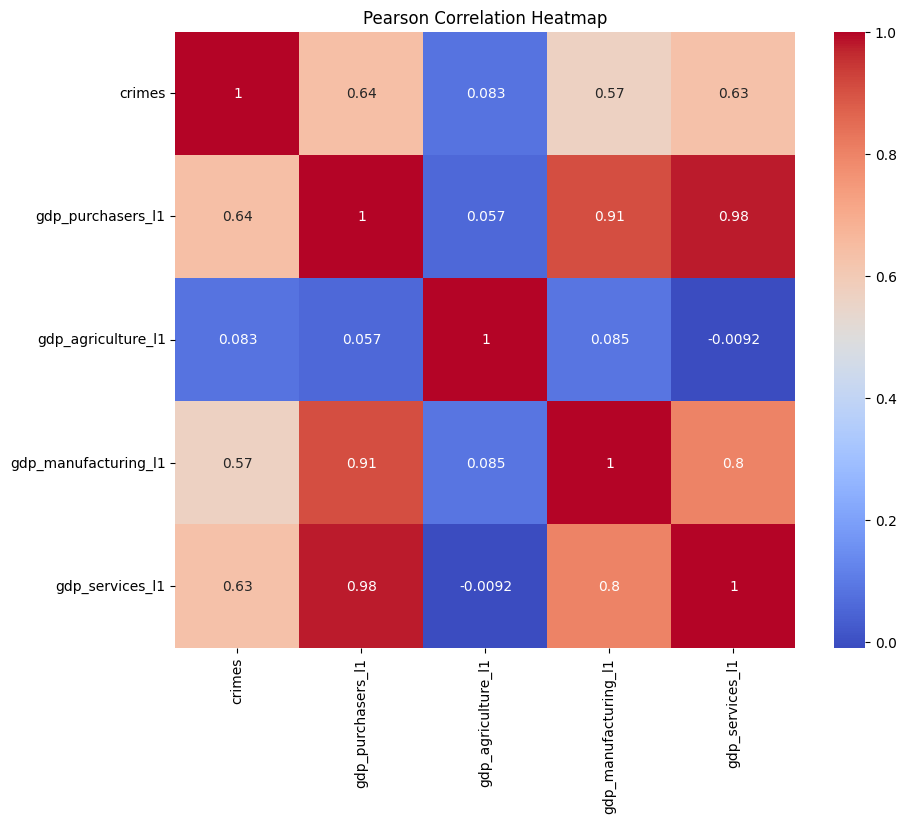

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

# Correlation heatmap with different correlation types
plt.figure(figsize=(10, 8))
sns.heatmap(df_lag.corr(method='pearson'), annot=True, cmap='coolwarm')
plt.title('Pearson Correlation Heatmap')
plt.show()

In [11]:
# From the correlation analysis,
# We see strong correlations in purchasers, manufacturing, and services to crimes.
# We see weak correlation in agriculture to crimes.
# There is also strong correlation between gdp_types
#  e.g. gdp_purchasers_l1 is strongly correlated to gdp_manufacturing_l1 and gdp_services_l1...
# 
# Hence, next steps:
# 1. Try models with and without agriculture as a feature.
# 2. Use models that can handle multicollinearity (correlation between independent variables)

# Modelling
Results: The final model is KNN Regressor with hyperparameters {'metric': 'euclidean', 'n_neighbors': 4, 'p': 1, 'weights': 'distance'}

Features: gdp_purchasers, gdp_manufacturing, and gdp_manufacturing. 
          All these features are of the year before.
          Because: We need to predict upcoming crime, hence will only have past gdp
          values.

Model selected: KNN regression with R2 0.752206 and Cross validation score 0.718310.

Decisions taken:
1. Select KNN regression over other models.
   Because this has superior performance over all other models in both its R2 (explains the 
   variability in the data) and CV score (is not overfitted).
2. Remove agriculture feature.
   Because this does not impact the performance significantly and in EDA, it was found to 
   have weak correlation to the target variable.
3. 

In [12]:
df_lag.to_csv("df_lag.csv")

## With agriculture

In [13]:
# Load feature and target
X = df_lag.drop(columns=['crimes'])
y = df_lag['crimes']
X.columns

Index(['gdp_purchasers_l1', 'gdp_agriculture_l1', 'gdp_manufacturing_l1',
       'gdp_services_l1'],
      dtype='object')

In [14]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Define models
models = [
    LinearRegression(),
    Ridge(),
    Lasso(),
    DecisionTreeRegressor(),
    RandomForestRegressor(),
    GaussianProcessRegressor(),
    KNeighborsRegressor(),
    SVR(),
    ElasticNet()
]

# Train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize evaluation dataframe
df_eval = pd.DataFrame(columns=['Model', 'MSE', 'R2', 'CV Score'])

# Evaluate each model
for model in models:
    model_name = model.__class__.__name__
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    cv_score = cross_val_score(model, X_train, y_train, cv=5).mean()
    df_eval = pd.concat([df_eval, pd.DataFrame({'Model': [model_name], 'MSE': [mse], 'R2': [r2], 'CV Score': [cv_score]})], ignore_index=True)

# Sort by CV Score and get top 3 models
top3 = df_eval.sort_values(by='CV Score', ascending=False).head()

C:\Users\Asad\AppData\Local\Temp\ipykernel_51952\1865503961.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_eval = pd.concat([df_eval, pd.DataFrame({'Model': [model_name], 'MSE': [mse], 'R2': [r2], 'CV Score': [cv_score]})], ignore_index=True)


In [15]:
# Display top 3 models
top3.head(100)

,Model,MSE,R2,CV Score
6,KNeighborsRegressor,0.183590,0.811343,0.743294
4,RandomForestRegressor,0.139174,0.856985,0.739856
7,SVR,0.343663,0.646852,0.657217
3,DecisionTreeRegressor,0.143632,0.852404,0.633838
8,ElasticNet,0.844439,0.132254,0.118033


In [16]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

# Define the model
knn = KNeighborsRegressor()

# Define the hyperparameter space
param_grid = {
    'n_neighbors': randint(3, 15),
    'weights': ['uniform', 'distance'],
    'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],
    'leaf_size': randint(10, 50)
}

# Perform randomized hyperparameter tuning
random_search = RandomizedSearchCV(knn, param_grid, cv=5, scoring='neg_mean_squared_error', n_iter=10)
random_search.fit(X_train, y_train)

# Print the best parameters and the best score
print("Best Parameters: ", random_search.best_params_)
print("Best Score: ", random_search.best_score_)


Best Parameters:  {'algorithm': 'kd_tree', 'leaf_size': 35, 'n_neighbors': 3, 'weights': 'distance'}
Best Score:  -0.19273497895706942


## Without agriculture

In [17]:
# Load feature and target
X = df_lag.drop(columns=['crimes', 'gdp_agriculture_l1'])
y = df_lag['crimes']
X.columns

Index(['gdp_purchasers_l1', 'gdp_manufacturing_l1', 'gdp_services_l1'], dtype='object')

In [18]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Define models
models = [
    LinearRegression(),
    Ridge(),
    Lasso(),
    DecisionTreeRegressor(),
    RandomForestRegressor(),
    GaussianProcessRegressor(),
    KNeighborsRegressor(),
    SVR(),
    ElasticNet()
]

# Train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize evaluation dataframe
df_eval = pd.DataFrame(columns=['Model', 'MSE', 'R2', 'CV Score'])

# Evaluate each model
for model in models:
    model_name = model.__class__.__name__
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    cv_score = cross_val_score(model, X_train, y_train, cv=5).mean()
    df_eval = pd.concat([df_eval, pd.DataFrame({'Model': [model_name], 'MSE': [mse], 'R2': [r2], 'CV Score': [cv_score]})], ignore_index=True)

# Sort by CV Score and get top 3 models
top3 = df_eval.sort_values(by='CV Score', ascending=False).head()

C:\Users\Asad\AppData\Local\Temp\ipykernel_51952\1865503961.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_eval = pd.concat([df_eval, pd.DataFrame({'Model': [model_name], 'MSE': [mse], 'R2': [r2], 'CV Score': [cv_score]})], ignore_index=True)


In [19]:
# Display top 3 models
top3.head(100)

,Model,MSE,R2,CV Score
6,KNeighborsRegressor,0.241139,0.752206,0.718310
4,RandomForestRegressor,0.251554,0.741503,0.689663
7,SVR,0.307226,0.684294,0.639601
3,DecisionTreeRegressor,0.497544,0.488724,0.597716
8,ElasticNet,0.844439,0.132254,0.118033


## Statistical Test to Confirm
Used to confirm whether including agriculture as a feature improves performance

In [20]:
from scipy.stats import ttest_rel  # Use paired t-test for dependent samples
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# Assuming df_lag is defined elsewhere and contains the lagged data
# y should also be defined as the target variable
assert 'crimes' in df_lag.columns, "Target column 'crimes' not found in df_lag"
assert 'gdp_agriculture_l1' in df_lag.columns, "Feature 'gdp_agriculture_l1' not found in df_lag"

# Define the model
knn1 = KNeighborsRegressor()
knn2 = KNeighborsRegressor()

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    df_lag.drop(columns=['crimes']),
    df_lag['crimes'],  # Assuming 'crimes' is the target
    test_size=0.2,
    random_state=42
)

# Create datasets with and without agriculture feature
X_train_with_agriculture = X_train
X_test_with_agriculture = X_test
X_train_without_agriculture = X_train.drop(columns=['gdp_agriculture_l1'])
X_test_without_agriculture = X_test.drop(columns=['gdp_agriculture_l1'])

# Fit the model on both datasets
knn_with_agriculture = knn1.fit(X_train_with_agriculture, y_train)
knn_without_agriculture = knn2.fit(X_train_without_agriculture, y_train)

# Predict on both datasets
y_pred_with_agriculture = knn_with_agriculture.predict(X_test_with_agriculture)
y_pred_without_agriculture = knn_without_agriculture.predict(X_test_without_agriculture)

# Calculate the R2 score for both predictions
r2_with_agriculture = r2_score(y_test, y_pred_with_agriculture)
r2_without_agriculture = r2_score(y_test, y_pred_without_agriculture)

# Calculate errors
errors_with_agriculture = y_test - y_pred_with_agriculture
errors_without_agriculture = y_test - y_pred_without_agriculture

# Perform a paired t-test to compare the errors
t_stat, p_value = ttest_rel(errors_with_agriculture, errors_without_agriculture)

# Print the results
print("R2 with Agriculture: ", r2_with_agriculture)
print("R2 without Agriculture: ", r2_without_agriculture)
print("T-statistic: ", t_stat)
print("P-value: ", p_value)

# Interpret the results
if p_value < 0.05:
    print("The performance difference from including the agriculture feature is statistically significant.")
else:
    print("The performance difference from including the agriculture feature is not statistically significant.")


R2 with Agriculture:  0.8113431686089806
R2 without Agriculture:  0.7522057010724617
T-statistic:  1.2848315861240653
P-value:  0.2002531754494763
The performance difference from including the agriculture feature is not statistically significant.


1. We found earlier that agriculture has a weak correlation to crime. 
2. By statistical test, it is confirmed removing it does not cause a significant drop in performance, we can remove the feature.

In conclusion, we decide to remove the agriculture variable from the model and finalise that as our model.

## Overfitting
Although selection based on the best CV score ensures we get the least overfitted model, </br>
we can still go the extra mile to check if this selected best model is indeed not overfitted.

Based on overfitting, we can then fine-tune the model through hyperparemeter tuning to reduce
</br>the overfitting.

In [21]:
# Compare train and test R2 performance of KNN regression model to prove no overfitting
# Train R2 performance
r2_train = r2_score(y_train, knn_without_agriculture.predict(X_train_without_agriculture))

# Test R2 performance 
r2_test = r2_score(y_test, y_pred_without_agriculture)

# Print the results
print("Train R2: ", r2_train)
print("Test R2: ", r2_test)

# Interpret the results
if abs(r2_train - r2_test) < 0.1:
    print("The model does not show signs of overfitting.")
else:
    print("The model may be overfitting.")

Train R2:  0.8740341228650935
Test R2:  0.7522057010724617
The model may be overfitting.


In [22]:
import numpy as np
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score

# Define parameter grid for KNN
param_grid = {
    'n_neighbors': np.arange(1, 31),
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan'],
    'p': [1, 2]  # p=1 for manhattan, p=2 for euclidean
}

# Initialize GridSearchCV to exhaustively search all parameter combinations
grid_search = GridSearchCV(
    KNeighborsRegressor(),
    param_grid=param_grid,
    cv=5,
    scoring=['r2', 'neg_mean_squared_error'],
    refit='r2',  # Use R2 score to select best model
    n_jobs=-1  # Use all CPU cores
)

# Fit GridSearchCV
grid_search.fit(X_train_without_agriculture, y_train)

# Get best parameters and scores
print("Best parameters:", grid_search.best_params_)
print("Best cross-validation R2 score:", grid_search.best_score_)

# Train model with best parameters
best_knn = grid_search.best_estimator_

# Get training and test R2 scores
best_r2_train = r2_score(y_train, best_knn.predict(X_train_without_agriculture))
best_r2_test = r2_score(y_test, best_knn.predict(X_test_without_agriculture))

# Calculate difference between train and test scores to check overfitting
r2_diff = abs(best_r2_train - best_r2_test)

print("\nBest model performance:")
print("Training R2:", best_r2_train)
print("Test R2:", best_r2_test)
print("R2 difference (train-test):", r2_diff)

# Determine overfitting status based on R2 difference
if r2_diff <= 0.05:
    overfitting_status = "Not overfitting"
elif r2_diff <= 0.1:
    overfitting_status = "Low overfitting"
elif r2_diff <= 0.2:
    overfitting_status = "Moderate overfitting"
else:
    overfitting_status = "High overfitting"

print("Overfitting status:", overfitting_status)

Best parameters: {'metric': 'euclidean', 'n_neighbors': 4, 'p': 1, 'weights': 'distance'}
Best cross-validation R2 score: 0.7538833933285225

Best model performance:
Training R2: 1.0
Test R2: 0.8108640833080516
R2 difference (train-test): 0.1891359166919484
Overfitting status: Moderate overfitting


In [23]:
# Define parameter grid for RandomForestRegressor
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Initialize GridSearchCV
grid_search = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring=['r2', 'neg_mean_squared_error'],
    refit='r2',
    n_jobs=-1
)

# Fit GridSearchCV
grid_search.fit(X_train_without_agriculture, y_train)

# Get best parameters and scores
print("Best parameters:", grid_search.best_params_)
print("Best cross-validation R2 score:", grid_search.best_score_)

# Train model with best parameters
best_rf = grid_search.best_estimator_

# Get training and test R2 scores
rf_r2_train = r2_score(y_train, best_rf.predict(X_train_without_agriculture))
rf_r2_test = r2_score(y_test, best_rf.predict(X_test_without_agriculture))

# Calculate difference between train and test scores to check overfitting
rf_r2_diff = abs(rf_r2_train - rf_r2_test)

print("\nBest Random Forest model performance:")
print("Training R2:", rf_r2_train)
print("Test R2:", rf_r2_test)
print("R2 difference (train-test):", rf_r2_diff)

# Determine overfitting status based on R2 difference
if rf_r2_diff <= 0.05:
    rf_overfitting_status = "Not overfitting"
elif rf_r2_diff <= 0.1:
    rf_overfitting_status = "Low overfitting"
elif rf_r2_diff <= 0.2:
    rf_overfitting_status = "Moderate overfitting"
else:
    rf_overfitting_status = "High overfitting"

print("Overfitting status:", rf_overfitting_status)


1. The KNN is moderately overfitted
2. The Random Forest is heavily overfitted
3. Both models are overfitted
4. The KNN model is proven to be better than the Random Forest

In conclusion, KNN model is selected as the best model.